In [1444]:
import cv2
import os
from google.colab.patches import cv2_imshow
from google. colab import runtime
import numpy as np
import PIL
from PIL import Image
import glob
import pathlib
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [1445]:
folder_path = '/content/drive/My Drive/kilobot_images/ref10'
image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff'))]

# Filter image files to keep only those starting with 'ref9_repeat'
filtered_image_files = [f for f in image_files if f.startswith('ref10_connectivity2')]

images = {}
for img_file in filtered_image_files:
    img_path = os.path.join(folder_path, img_file)
    img = cv2.imread(img_path)
    if img is not None:
        images[img_file] = img
    else:
        print(f"Warning: Could not load image {img_file}")

print(f"Loaded {len(images)} images.")

Loaded 1 images.


ref10_connectivity2.png


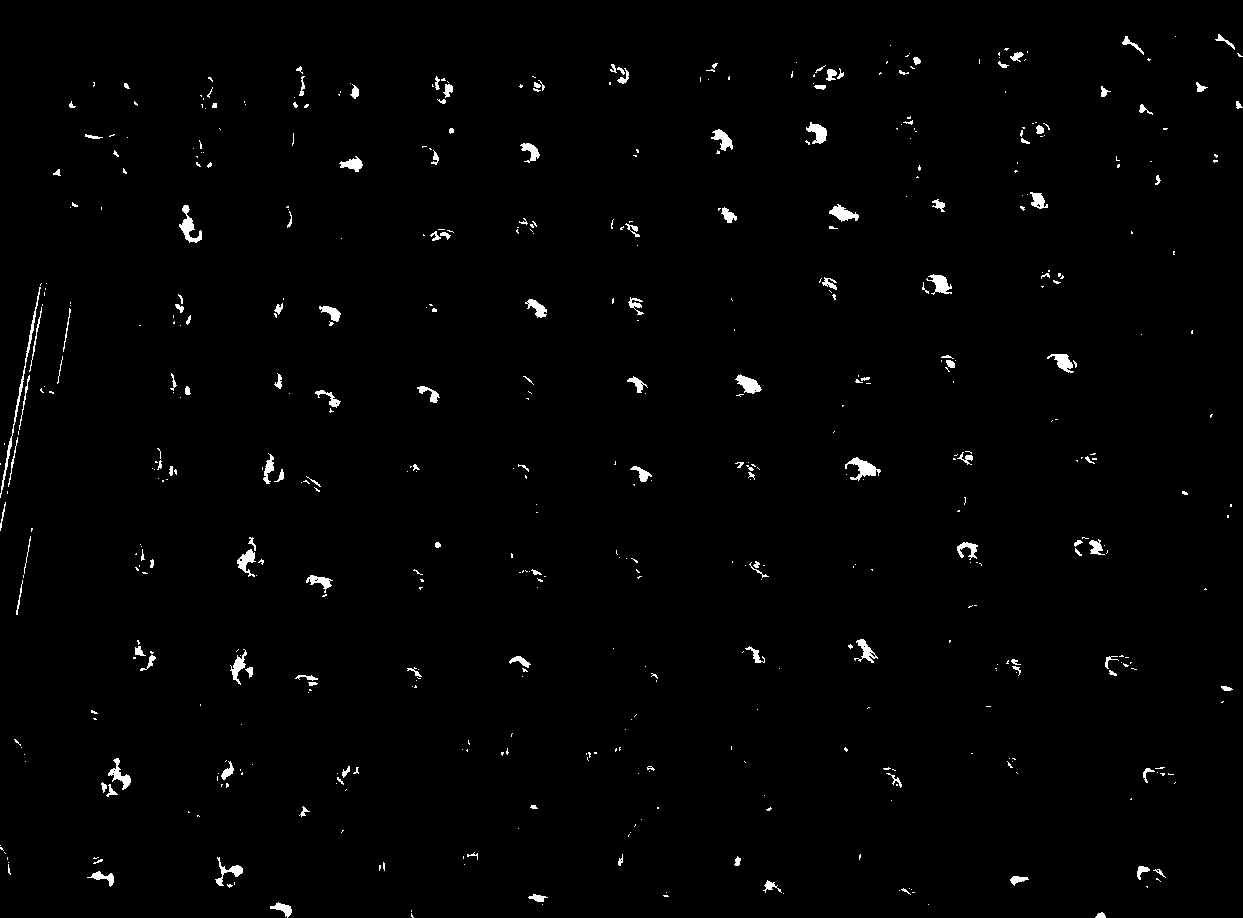

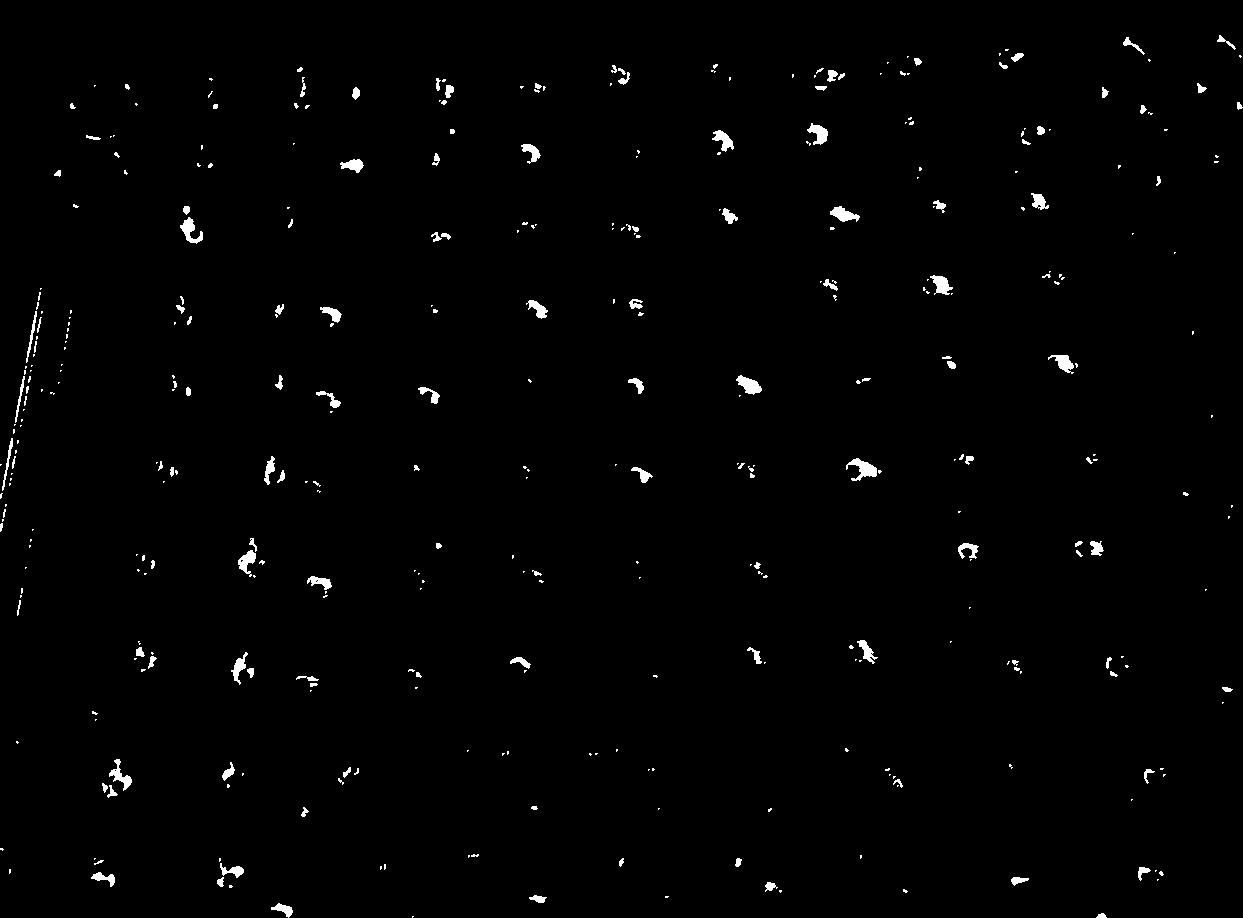

In [1459]:
image_number = 0
image_name = list(images.keys())[image_number] #This gets an image that the user defines
print(image_name)
#Gets the image from drive
image = list(images.items())[image_number][1]
#cv2_imshow(image)

hsv = image.copy()
hsv = cv2.cvtColor(hsv, cv2.COLOR_BGR2HSV)

# cv2_imshow(hsv)

s = hsv.copy()
s = s[:, :, 1]

# cv2_imshow(s)

s_grey = s.copy()

(thresh, s_binary) = cv2.threshold(s, 90, 255, cv2.THRESH_BINARY)

cv2_imshow(s_binary)

gradient = cv2.morphologyEx(s_binary, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2,2)))
cv2_imshow(gradient)

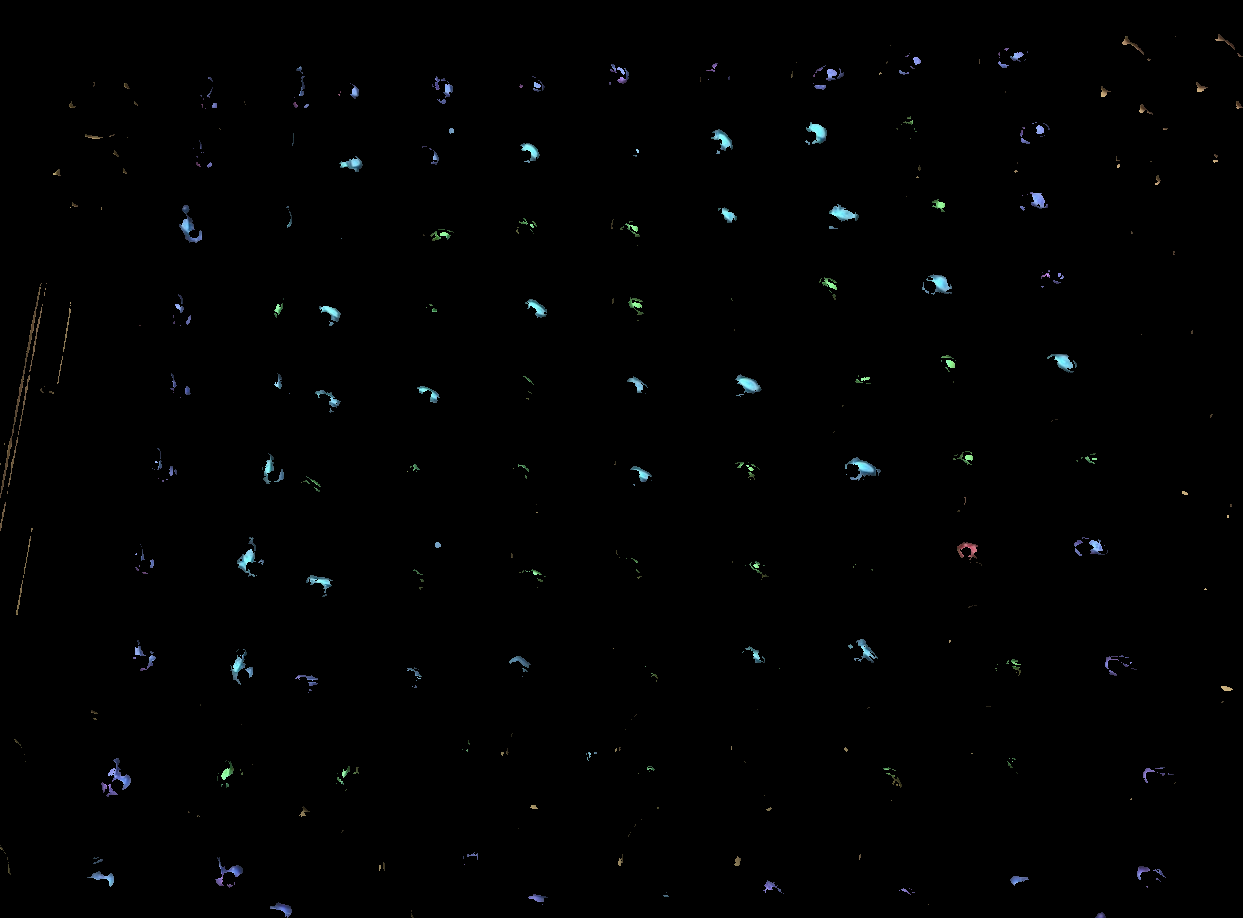

In [1460]:
#Makes the final mask
final = cv2.bitwise_or(image, image, mask = s_binary)
cv2_imshow(final)

b = final.copy()
b = b[:, :, 0]

r = final.copy()
r = r[:, :, 2]

# #cv2_imshow(b)
# cv2_imshow(r)



In [ ]:
(thresh, b_binary) = cv2.threshold(b, 140, 255, cv2.THRESH_BINARY)
#cv2_imshow(b_binary)

(thresh, r_binary) = cv2.threshold(r, 140, 255, cv2.THRESH_BINARY)
#cv2_imshow(r_binary)

In [ ]:
b_binary1 = cv2.morphologyEx(b_binary, cv2.MORPH_ERODE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2)))
b_binary2 = cv2.morphologyEx(b_binary1, cv2.MORPH_DILATE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (12, 12)))
#cv2_imshow(b_binary2)

r_binary1 = cv2.morphologyEx(r_binary, cv2.MORPH_ERODE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2)))
r_binary2 = cv2.morphologyEx(r_binary1, cv2.MORPH_DILATE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (12, 12)))
#cv2_imshow(r_binary2)

In [ ]:
#Finds contours allowing for red colour to be found
r_contours = cv2.findContours(r_binary2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
r_contours = r_contours[0] if len(r_contours) == 2 else r_contours[1]

#Makes lists to store x,y coords and the mid points of the rectangles
r_x_total =[]
r_y_total = []
r_mid_point_x = []
r_mid_point_y = []
r_img = image.copy()
#Counts the amount of red lights present in the picture
amount_of_r = 0
amount_of_b = 0


In [ ]:
import cv2
import numpy as np
import itertools

# === Detect red and blue contours ===
r_contours = cv2.findContours(r_binary2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
r_contours = r_contours[0] if len(r_contours) == 2 else r_contours[1]

b_contours = cv2.findContours(b_binary2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
b_contours = b_contours[0] if len(b_contours) == 2 else b_contours[1]

# === Combine all contours ===
all_contours = r_contours + b_contours

# === Extract bounding boxes and midpoints, tagged with color ===
boxes = []
widths = []

def add_boxes(contours, colour):
    for cntr in contours:
        x, y, w, h = cv2.boundingRect(cntr)
        widths.append(w)
        boxes.append({
            "x": x,
            "y": y,
            "w": w,
            "h": h,
            "cx": x + w / 2,
            "cy": y + h / 2,
            "colour": colour,  # 🟥 or 🟦
        })

add_boxes(r_contours, 65504)
add_boxes(b_contours, -65504)

# find average distance between boxes
centroids = np.array([[b["cx"], b["cy"]] for b in boxes])
dists = []
for a, b in itertools.combinations(centroids, 2):
    dist = np.linalg.norm(a - b)
    dists.append(dist)

# Compute average
avg_dist = np.mean(dists)
print(f"Average distance between all boxes: {avg_dist:.2f} pixels")


# === Estimate average distance threshold ===
avg_w = np.mean(widths)


Average distance between all boxes: 576.88 pixels


In [ ]:
# === Sort boxes using distance-based row sweep ===
DIST_THRESH = 110 #8 * avg_w  # can tune
ordered = []
remaining = boxes.copy()

def distance(b1, b2):
    return np.sqrt((b1["cx"] - b2["cx"])**2 + (b1["cy"] - b2["cy"])**2)

array = []
idx = 0
while remaining:
    # 1. Start from the top-rightmost box
    top_y = min(b["cy"] for b in remaining) # highest box
    top_boxes = [b for b in remaining if abs(b["cy"] - top_y) < avg_w+ 5] # must be at least one box near the top
    current = max(top_boxes, key=lambda b: b["cx"])

    ordered.append(current)
    remaining.remove(current)

    while True:
        current['idx'] = idx
        # 2. Find candidates to the left within distance threshold
        candidates = [
            b for b in remaining
            # if on the left and within threshold (bigger threshold -> needs to be further left)
            # and with distance threshold of what counts as neighbour
            # and next cy needs to be not too much lower (bigger) - bigger number more forgiving
            if b["cx"] < (current["cx"] - 20) and distance(b, current) < DIST_THRESH and (b["cy"] < current["cy"] + 40)
        ]
        idx += 1
        if not candidates:
            break

        # 3. Choose the closest one
        # choose the highest one
        next_box = min(candidates, key=lambda b: b['y'])
        ordered.append(next_box)
        remaining.remove(next_box)
        current = next_box


# === Draw labels and boxes ===
labelled_img = image.copy()

for idx, box in enumerate(ordered, start=1):
    x, y, w, h = box["x"], box["y"], box["w"], box["h"]
    color_map = {
        65504: (0, 0, 255),    # Red
        -65504: (255, 0, 0),    # Blue
    }

    box_color = color_map.get(box["colour"], (0, 255, 0))  # default green if missing
    cv2.rectangle(labelled_img, (x, y), (x + w, y + h), box_color, 2)
    label_text = f"{idx-1}"
    cv2.putText(labelled_img, label_text, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

cv2_imshow(labelled_img)
print("Total detected objects:", len(ordered))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
def dummy_box(colour, index):
  if colour == "red":
    colour = 65504
  elif colour == "blue":
    colour = -65504
  else:
    colour = 0

  dummy = {
      #"index": index,          # placeholder label
      "colour": colour,       # or "missing", or "dummy"
      "x": 450,
      "y": 600,
      "w": 22,
      "h": 26,
      "cx": 316,
      "cy": 600
  }

  return dummy



index = 19 # adds itself BEFORE
dummy_box = dummy_box("none", index)

In [ ]:
# adds BEFORE index
insert_at = next((i for i, box in enumerate(ordered) if box.get("idx") == index), None)
ordered.insert(insert_at, dummy_box)
len(ordered)

96

In [ ]:
idx_to_remove = 40
boxes = [box for box in boxes if box.get("idx") != idx_to_remove]


In [ ]:
distance(ordered[82], ordered[86])

np.float64(140.91131963046828)

In [ ]:
idx_to_remove = 17
ordered = [box for box in ordered if box.get("idx") != idx_to_remove]


In [ ]:
ordered.append(dummy_box)
len(ordered)

100

In [ ]:
neighbour_idx = [36, 46, 53, 54]
neighbours = [b for b in ordered if b.get("idx") in neighbour_idx]

print(neighbours)
len(neighbours)

[{'x': 557, 'y': 372, 'w': 21, 'h': 18, 'cx': 567.5, 'cy': 381.0, 'colour': 65504, 'idx': 36}, {'x': 666, 'y': 438, 'w': 24, 'h': 26, 'cx': 678.0, 'cy': 451.0, 'colour': 65504, 'idx': 46}, {'x': 564, 'y': 528, 'w': 16, 'h': 16, 'cx': 572.0, 'cy': 536.0, 'colour': 65504, 'idx': 53}, {'x': 467, 'y': 470, 'w': 25, 'h': 16, 'cx': 479.5, 'cy': 478.0, 'colour': 65504, 'idx': 54}]


4

In [ ]:
avg_cx = np.mean([b['cx'] for b in neighbours])
avg_cy = np.mean([b['cy'] for b in neighbours])
avg_w = np.mean([b['w'] for b in neighbours])
avg_h = np.mean([b['h'] for b in neighbours])

new_box = {
    'x': int(avg_cx - avg_w / 2),
    'y': int(avg_cy - avg_h / 2) + 10,
    'w': int(avg_w),
    'h': int(avg_h),
    'cx': avg_cx,
    'cy': avg_cy,
    'colour': -65504,
}

for key in ['x', 'y', 'w', 'h']:
    new_box[key] = int(new_box[key])

new_box['colour'] = 65504
print(new_box)

{'x': 563, 'y': 462, 'w': 21, 'h': 19, 'cx': np.float64(574.25), 'cy': np.float64(461.5), 'colour': 65504}


In [ ]:
boxes.append(new_box)

In [ ]:
boxes.append(dummy_box)
len(boxes)

99

In [ ]:
array[75] = -65504

In [ ]:
ordered[60] #["colour"] = -65504
# ordered[78]["colour"] = -65504
# ordered[79]["colour"] = -65504

{'colour': 0, 'x': 450, 'y': 600, 'w': 22, 'h': 26, 'cx': 316, 'cy': 600}

In [ ]:
ordered.remove(ordered[60])
len(ordered)

100

In [ ]:
array = [item["colour"] for item in ordered]
print(len(array))
print(array)


100
[65504, 0, 65504, -65504, -65504, 65504, 65504, -65504, 0, -65504, -65504, -65504, 0, 0, 0, 65504, -65504, 0, 0, 65504, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -65504, 65504, 0, 0, 0, 0, 0, 0, 0, 65504, 65504, 65504, 65504, 0, -65504, -65504, 0, 0, 0, 65504, 65504, 65504, -65504, 0, 65504, 65504, 0, 0, 0, -65504, 0, 65504, -65504, 0, 65504, 65504, 65504, 0, 0, 0, 0, 65504, -65504, 0, 65504, 65504, 65504, 65504, -65504, 0, 0, 0, 0, 0, 0, 0, 0, 0, -65504, -65504, 0, 0, 0, 0]


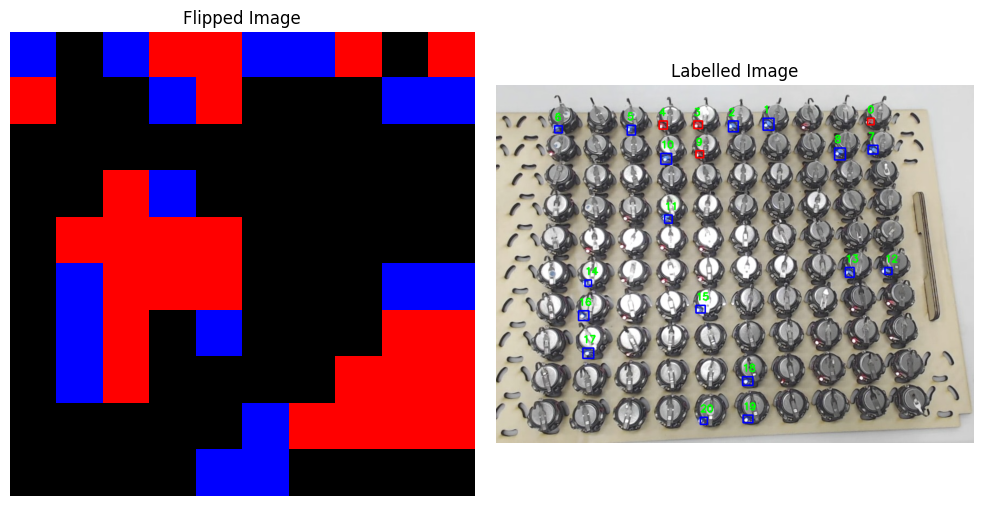

In [ ]:
array = np.array(array)
array_grid = array.reshape((10, 10))
height, width = array_grid.shape
img_rgb = np.zeros((height, width, 3), dtype=np.uint8)

# Map values to colors:
# 65504 -> red (255,0,0)
# -65504 -> blue (0,0,255)

img_rgb[array_grid == 65504] = [255, 0, 0]    # red
img_rgb[array_grid == -65504] = [0, 0, 255]   # blue

# Optionally: for any other values, keep black (0,0,0)
flipped_img = cv2.flip(img_rgb, 1)

ig, axs = plt.subplots(1, 2, figsize=(10, 5))  # 1 row, 2 columns

# First image
axs[0].imshow(flipped_img)
axs[0].axis('off')
axs[0].set_title('Flipped Image')

# Second image
axs[1].imshow(cv2.cvtColor(labelled_img, cv2.COLOR_BGR2RGB))
axs[1].axis('off')
axs[1].set_title('Labelled Image')

plt.tight_layout()
plt.show()


In [ ]:
print(image_name)

ref23_repeat5_phase2.png


In [ ]:
try:
    existing = dict(np.load('/content/drive/MyDrive/kilobot_images/ref23.npz'))
except FileNotFoundError:
    existing = {}

# Add new array
existing['repeat5_phase2'] = array

# Save updated .npz
np.savez('/content/drive/MyDrive/kilobot_images/ref23.npz', **existing)